In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Dataset shape and basic info
print("Shape:", df.shape)
print("\nData Types & Counts:")
df.info()
df.head()


Shape: (7043, 21)

Data Types & Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pa

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Convert TotalCharges empty spaces to NaN, fill with 0, and convert to float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan)).fillna(0)

# Drop identifier column
df.drop(columns=['customerID'], inplace=True)

# Confirm no missing values or bad data types remain
print("Missing values after cleaning:", df.isnull().sum().sum())
print("TotalCharges type:", df['TotalCharges'].dtype)


Missing values after cleaning: 0
TotalCharges type: float64


/tmp/ipykernel_2519/106937338.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', ax=axes[0], palette='Set2')


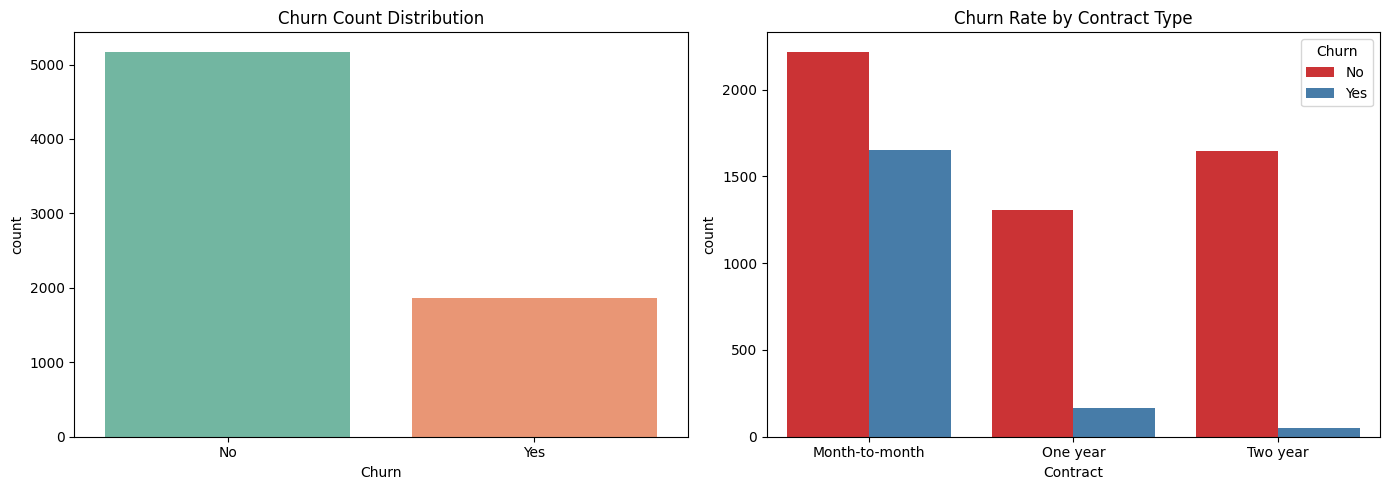

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target distribution
sns.countplot(data=df, x='Churn', ax=axes[0], palette='Set2')
axes[0].set_title('Churn Count Distribution')

# Churn by Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[1], palette='Set1')
axes[1].set_title('Churn Rate by Contract Type')

plt.tight_layout()
plt.show()


In [5]:
from sklearn.model_selection import train_test_split

# Encode target Churn as binary (1/0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# One-Hot Encode categorical features
df_encoded = pd.get_dummies(df, drop_first=True)

# Separate X and y
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (5634, 30)
Testing set shape: (1409, 30)


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    print(f"{name} Confusion Matrix")
    print(confusion_matrix(y_test, y_pred))
    print("\n")


Logistic Regression Confusion Matrix
[[925 110]
 [162 212]]


Random Forest Confusion Matrix
[[920 115]
 [188 186]]




In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4)
    })

metrics_df = pd.DataFrame(results)
display(metrics_df)


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.807,0.6584,0.5668,0.6092
1,Random Forest,0.785,0.6179,0.4973,0.5511


In [7]:
# Predict for the first customer in test set
sample = X_test.iloc[[0]]
pred = models["Random Forest"].predict(sample)[0]
actual = y_test.iloc[0]

label_map = {1: "Churn (Will Leave)", 0: "No Churn (Will Stay)"}

print(f"Model Prediction : {label_map[pred]}")
print(f"Actual Result    : {label_map[actual]}")


Model Prediction : No Churn (Will Stay)
Actual Result    : No Churn (Will Stay)
